# Lab 5: Hierarchical and DBSCAN Clustering on the Wine Dataset

**Student:** Vineela Reddy Karnatakam  
**Course:** MSCS-634 — Advanced Big Data and Data Mining  
**Assignment:** Lab 5 — Hierarchical and DBSCAN Clustering  
**Dataset:** `sklearn.datasets.load_wine` (178 samples, 13 numeric features)

**Objective:** Explore and compare agglomerative hierarchical clustering and DBSCAN after feature standardization, using dendrograms, PCA visualizations, and quantitative metrics.

## 1. Data preparation and exploration
We inspect the 13 Wine measurements, check for missing values, and standardize features. We use the provided wine class labels **only for external validation** (homogeneity and completeness), not for fitting either clustering algorithm.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, homogeneity_score, completeness_score
from scipy.cluster.hierarchy import linkage, dendrogram
from IPython.display import display

RANDOM_STATE = 42
wine = load_wine()
df = pd.DataFrame(wine.data, columns=wine.feature_names)
y_true = wine.target
print(f"Shape: {df.shape}; known classes: {np.unique(y_true)}")
print("First five rows:")
display(df.head())
print("Data types and nulls:")
df.info()
print("Summary statistics:")
display(df.describe().round(2))
print("Missing values:", int(df.isna().sum().sum()), "| Duplicate rows:", int(df.duplicated().sum()))
X = StandardScaler().fit_transform(df)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
print('PCA (2 components) explained variance:', np.round(pca.explained_variance_ratio_, 3), '| total:', round(pca.explained_variance_ratio_.sum(), 3))

Shape: (178, 13); known classes: [0 1 2]
First five rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


Data types and nulls:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00
mean,13.00,2.34,2.37,19.49,99.74,2.30,2.03,0.36,1.59,5.06,0.96,2.61,746.89
std,0.81,1.12,0.27,3.34,14.28,0.63,1.00,0.12,0.57,2.32,0.23,0.71,314.91
min,11.03,0.74,1.36,10.60,70.00,0.98,0.34,0.13,0.41,1.28,0.48,1.27,278.00
25%,12.36,1.60,2.21,17.20,88.00,1.74,1.20,0.27,1.25,3.22,0.78,1.94,500.50
50%,13.05,1.87,2.36,19.50,98.00,2.36,2.13,0.34,1.56,4.69,0.96,2.78,673.50
75%,13.68,3.08,2.56,21.50,107.00,2.80,2.88,0.44,1.95,6.20,1.12,3.17,985.00
max,14.83,5.80,3.23,30.00,162.00,3.88,5.08,0.66,3.58,13.00,1.71,4.00,1680.00


Missing values: 0 | Duplicate rows: 0
PCA (2 components) explained variance: [0.362 0.192] | total: 0.554


## 2. Hierarchical clustering
Agglomerative clustering with Ward linkage merges groups to minimize within-cluster variance. We compare 2, 3, 4, and 5 groups using silhouette (internal separation) and homogeneity/completeness (agreement with known wine classes). The two-dimensional PCA plots are visual aids; clustering is computed on all **13 standardized features**.

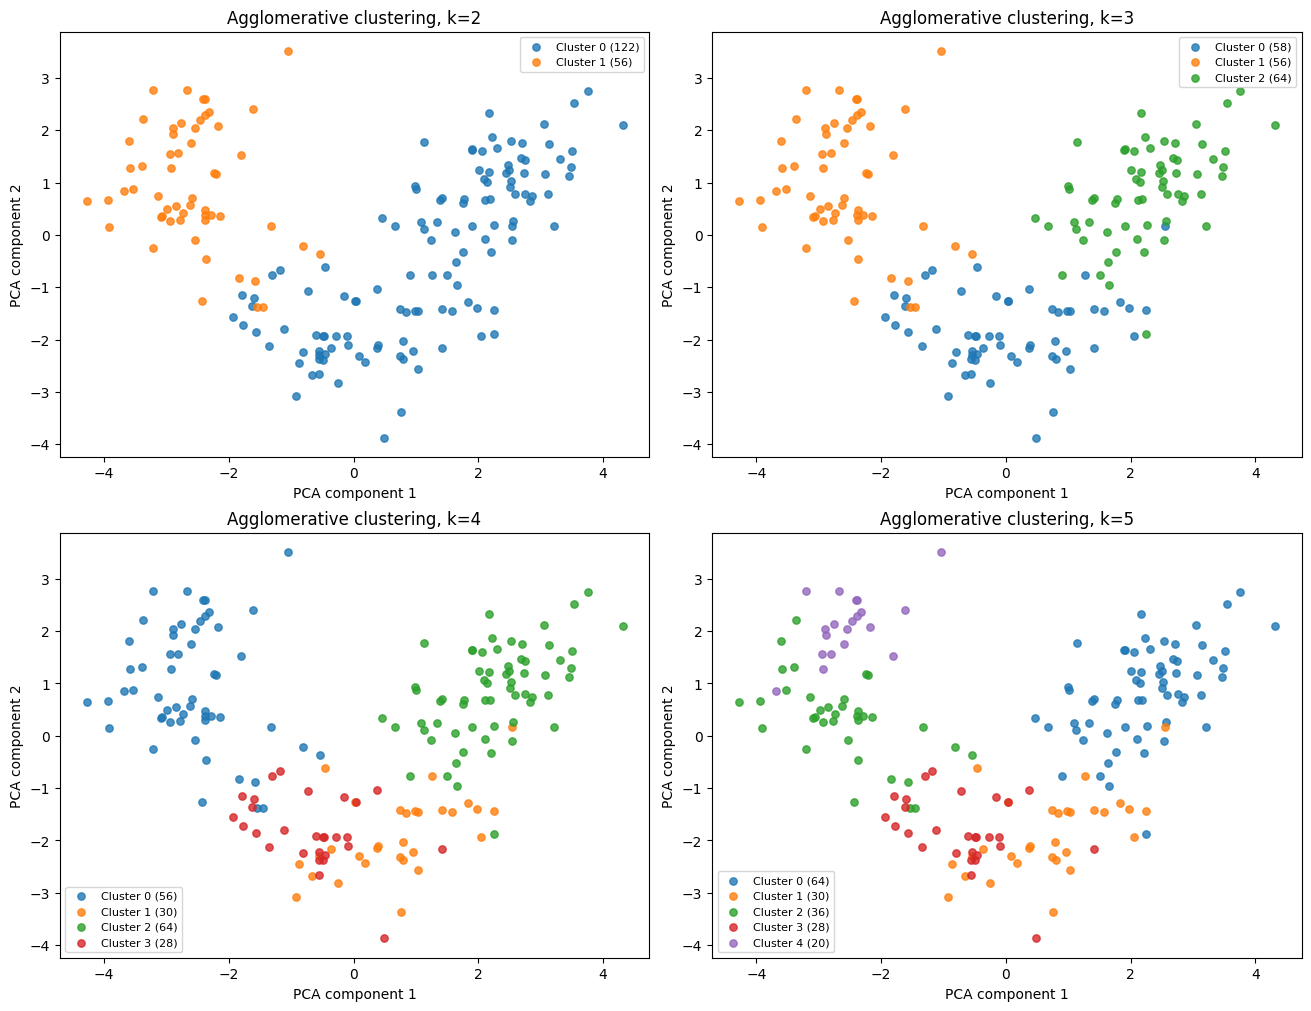

,n_clusters_parameter,clusters,noise_points,noise_pct,silhouette_assigned_only,homogeneity_all,completeness_all
0,2,2,0,0.0,0.267,0.444,0.774
1,3,3,0,0.0,0.277,0.790,0.783
2,4,4,0,0.0,0.226,0.790,0.649
3,5,5,0,0.0,0.187,0.811,0.576


In [ ]:
def evaluate(labels, X, truth):
    labels = np.asarray(labels)
    clusters = sorted(set(labels) - {-1})
    noise_count = int(np.sum(labels == -1))
    # Silhouette is computed over assigned (non-noise) points so a noise label
    # is not misleadingly considered an ordinary cluster.
    mask = labels != -1
    assigned_labels = labels[mask]
    score = np.nan
    if len(set(assigned_labels)) >= 2 and len(assigned_labels) > len(set(assigned_labels)):
        score = silhouette_score(X[mask], assigned_labels)
    # External scores are evaluated on all samples, including DBSCAN noise (-1),
    # so that the scores reflect the complete clustering assignment.
    return {
        'clusters': len(clusters), 'noise_points': noise_count,
        'noise_pct': round(100 * noise_count / len(labels), 1),
        'silhouette_assigned_only': score,
        'homogeneity_all': homogeneity_score(truth, labels),
        'completeness_all': completeness_score(truth, labels),
    }

def plot_clusters(ax, coords, labels, title):
    labels = np.asarray(labels)
    distinct = sorted(set(labels))
    cmap = plt.get_cmap('tab10')
    for i, label in enumerate(distinct):
        mask = labels == label
        if label == -1:
            ax.scatter(coords[mask, 0], coords[mask, 1], c='black', marker='x', s=45, label=f'Noise ({mask.sum()})', alpha=.75)
        else:
            ax.scatter(coords[mask, 0], coords[mask, 1], color=cmap(i % 10), s=28, alpha=.8, label=f'Cluster {label} ({mask.sum()})')
    ax.set(title=title, xlabel='PCA component 1', ylabel='PCA component 2')
    ax.legend(fontsize=8)

hier_labels = {}
hier_rows = []
fig, axes = plt.subplots(2, 2, figsize=(13, 10), constrained_layout=True)
for ax, k in zip(axes.ravel(), [2, 3, 4, 5]):
    labels = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X)
    hier_labels[k] = labels
    hier_rows.append({'n_clusters_parameter': k, **evaluate(labels, X, y_true)})
    plot_clusters(ax, X_pca, labels, f'Agglomerative clustering, k={k}')
plt.show()
hier_results = pd.DataFrame(hier_rows)
display(hier_results.round(3))

### Ward dendrogram
The dendrogram displays the nested merge hierarchy. Large vertical merge heights suggest well-separated groups. We draw a horizontal guide for a three-cluster cut; this visualization is indicative rather than definitive and its branches are built from all standardized dimensions.

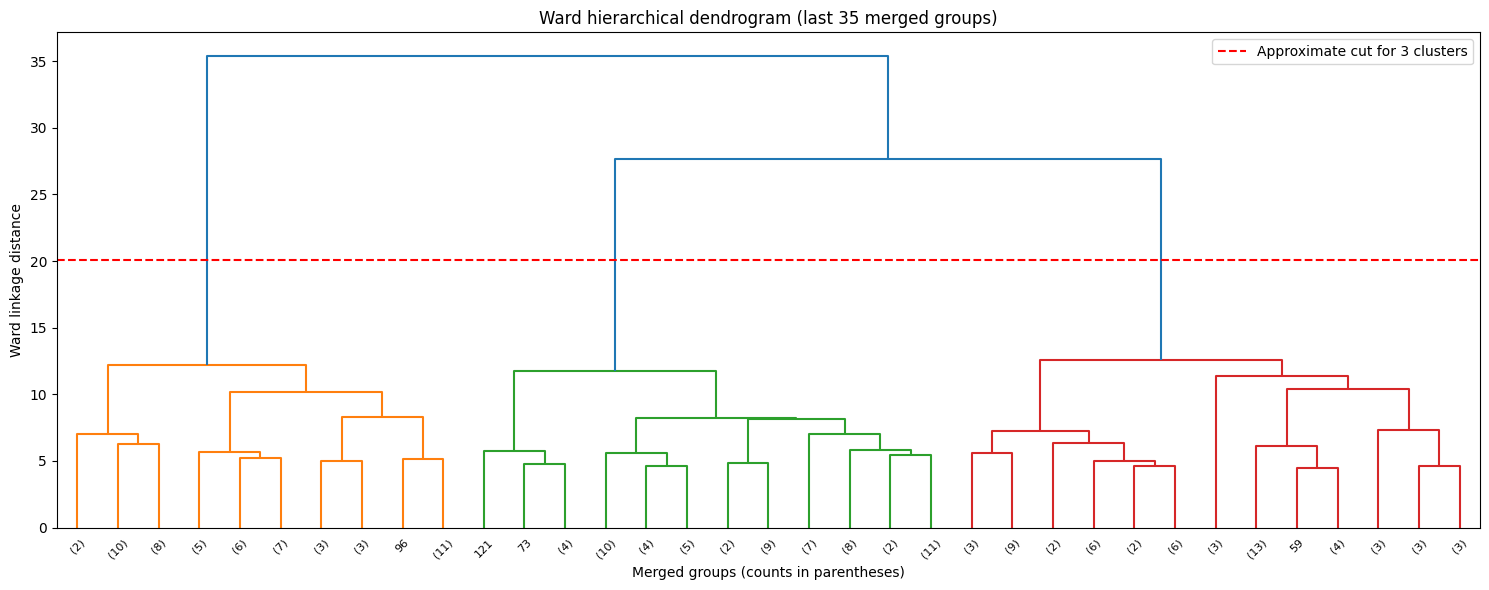

In [ ]:
Z = linkage(X, method='ward')
fig, ax = plt.subplots(figsize=(15, 6))
dendrogram(Z, ax=ax, truncate_mode='lastp', p=35, show_leaf_counts=True)
ax.set(title='Ward hierarchical dendrogram (last 35 merged groups)', xlabel='Merged groups (counts in parentheses)', ylabel='Ward linkage distance')
# Height at which three groups remain (between the merges to 3 and 2 groups).
cut_three = (Z[-3, 2] + Z[-2, 2]) / 2
ax.axhline(cut_three, color='red', linestyle='--', label='Approximate cut for 3 clusters')
ax.legend()
plt.tight_layout()
plt.show()

## 3. DBSCAN clustering
DBSCAN groups dense neighborhoods and marks sparse points as noise (`-1`). We compare different neighborhood radii (`eps`) and density thresholds (`min_samples`). Small `eps` often creates many noise points, while large `eps` can merge clusters. 

**Metric convention:** Silhouette uses only non-noise assignments, and is undefined (`NaN`) when fewer than 2 valid clusters exist. Homogeneity and completeness use all samples including the noise label; interpret them alongside cluster counts and noise percentage, because extreme noise assignments can make scores misleading.

In [ ]:
from itertools import product
settings = list(product([1.5, 2.0, 2.5, 3.0, 3.5], [3, 5, 10]))
db_labels = {}
db_rows = []
for eps, min_samples in settings:
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
    db_labels[(eps, min_samples)] = labels
    db_rows.append({'eps': eps, 'min_samples': min_samples, **evaluate(labels, X, y_true)})
db_results = pd.DataFrame(db_rows)
display(db_results.round(3))

,eps,min_samples,clusters,noise_points,noise_pct,silhouette_assigned_only,homogeneity_all,completeness_all
0,1.5,3,8,147,82.6,0.331,0.189,0.251
1,1.5,5,0,178,100.0,NaN,0.000,1.000
2,1.5,10,0,178,100.0,NaN,0.000,1.000
3,2.0,3,5,64,36.0,0.211,0.442,0.372
4,2.0,5,5,85,47.8,0.240,0.362,0.325
5,2.0,10,1,139,78.1,NaN,0.289,0.596
6,2.5,3,1,23,12.9,NaN,0.067,0.189
7,2.5,5,1,24,13.5,NaN,0.058,0.158
8,2.5,10,2,32,18.0,0.323,0.504,0.560
9,3.0,3,2,7,3.9,0.239,0.031,0.135


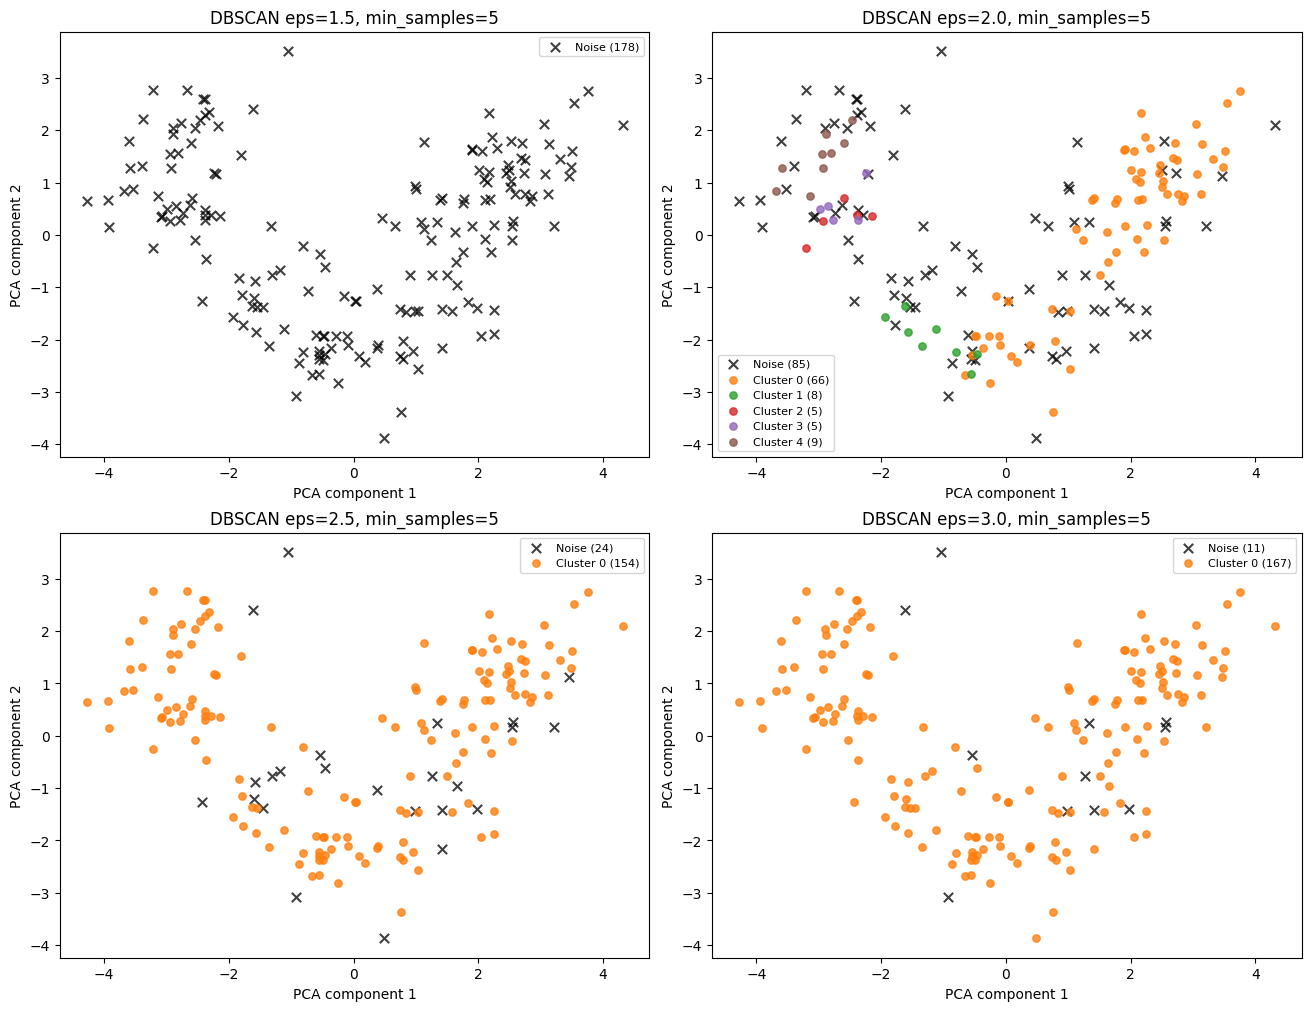

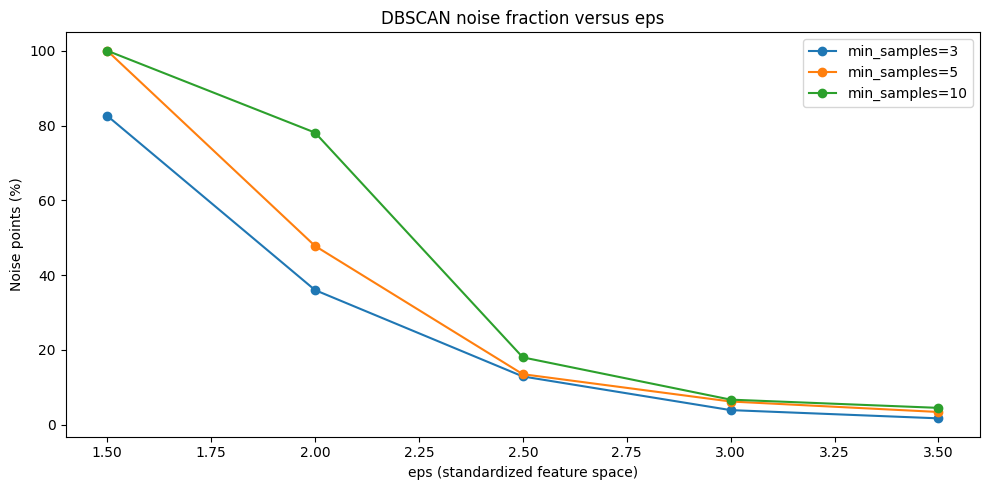

In [ ]:
# Plot representative parameter cases spanning more/less aggressive neighborhood definitions.
examples = [(1.5, 5), (2.0, 5), (2.5, 5), (3.0, 5)]
fig, axes = plt.subplots(2, 2, figsize=(13, 10), constrained_layout=True)
for ax, params in zip(axes.ravel(), examples):
    plot_clusters(ax, X_pca, db_labels[params], f'DBSCAN eps={params[0]}, min_samples={params[1]}')
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
for min_samples in [3, 5, 10]:
    subset = db_results[db_results.min_samples == min_samples]
    ax.plot(subset.eps, subset.noise_pct, marker='o', label=f'min_samples={min_samples}')
ax.set(title='DBSCAN noise fraction versus eps', xlabel='eps (standardized feature space)', ylabel='Noise points (%)')
ax.legend()
plt.tight_layout()
plt.show()

## 4. Comparison, interpretation, and reflection
The following code picks the strongest valid DBSCAN model **by non-noise silhouette** for a data-driven summary, while excluding degenerate one-cluster/all-noise outcomes. We also display the best hierarchical choice using silhouette. The highest silhouette alone does **not** necessarily mean the best result: inspect coverage (fraction assigned) and external scores.

In [ ]:
best_h = hier_results.sort_values('silhouette_assigned_only', ascending=False).iloc[0]
valid_db = db_results[(db_results.clusters >= 2) & (db_results.noise_points < len(X))].dropna(subset=['silhouette_assigned_only'])
print('Best hierarchical configuration (highest silhouette):')
display(best_h.to_frame().T.round(3))
if not valid_db.empty:
    best_db = valid_db.sort_values('silhouette_assigned_only', ascending=False).iloc[0]
    print('Best DBSCAN configuration among models with >=2 clusters:')
    display(best_db.to_frame().T.round(3))
    print(f"Note: this DBSCAN selection marks {best_db['noise_pct']:.1f}% of observations as noise; compare coverage before deciding which method is more useful.")
else:
    print('No DBSCAN configuration produced >=2 non-noise clusters; silhouette is undefined for the tested grid.')

print('Hierarchical strengths: interpretable nested grouping, dendrogram, explicit cluster count.')
print('Hierarchical limitations: choosing k and sensitivity to linkage/scaling; no explicit noise category.')
print('DBSCAN strengths: detects density-based groups, explicitly identifies outliers/noise, no preset k.')
print('DBSCAN limitations: eps/min_samples sensitive; high-dimensional distance concentration; a single density threshold may fail on variable-density groups.')

Best hierarchical configuration (highest silhouette):


,n_clusters_parameter,clusters,noise_points,noise_pct,silhouette_assigned_only,homogeneity_all,completeness_all
1,3.0,3.0,0.0,0.0,0.277,0.79,0.783


Best DBSCAN configuration among models with >=2 clusters:


,eps,min_samples,clusters,noise_points,noise_pct,silhouette_assigned_only,homogeneity_all,completeness_all
0,1.5,3.0,8.0,147.0,82.6,0.331,0.189,0.251


Note: this DBSCAN selection marks 82.6% of observations as noise; compare coverage before deciding which method is more useful.
Hierarchical strengths: interpretable nested grouping, dendrogram, explicit cluster count.
Hierarchical limitations: choosing k and sensitivity to linkage/scaling; no explicit noise category.
DBSCAN strengths: detects density-based groups, explicitly identifies outliers/noise, no preset k.
DBSCAN limitations: eps/min_samples sensitive; high-dimensional distance concentration; a single density threshold may fail on variable-density groups.


### Written observations and conclusions

- **Preprocessing:** Standardization is essential because Wine variables have very different units and ranges. Without it, large-scale features could dominate Euclidean distances and Ward linkage.
- **Hierarchical:** Changing `n_clusters` from 2 to 5 alters the granularity of the groups. A dendrogram reveals how nested groups combine, helping assess plausible cuts. Because the dataset has three known classes, `k=3` is a useful point of comparison, **not** proof that it is optimal.
- **DBSCAN:** Smaller `eps` typically labels more observations as noise; increasing `eps` often joins previously separate dense regions. Larger `min_samples` raises the density requirement and can increase noise. The summary table quantifies these patterns.
- **Evaluation:** Silhouette measures cohesion/separation in feature space; homogeneity evaluates whether predicted clusters contain a single true class; completeness evaluates whether members of each true class mostly fall in one cluster. DBSCAN metrics need care when many points are noise.
- **Conclusion:** Hierarchical clustering generally gives a clearer complete partition and interpretable merge hierarchy for this small standardized dataset; DBSCAN is useful for studying density structure and potential outliers, but may struggle to separate Wine varieties across 13 features. These are exploratory findings, not supervised predictive accuracy.

**References:** Scikit-learn documentation: [AgglomerativeClustering](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.AgglomerativeClustering.html), [DBSCAN](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html), [Clustering metrics](https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation); SciPy [dendrogram](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.dendrogram.html).